# Stiff reaction-diffusion at scale

In this tutorial, we follow two chemicals that react and diffuse on a periodic square, where a few seeded spots divide until they fill it. The parameters are the "spots" regime of the [Gray-Scott dataset](https://polymathic-ai.org/the_well/datasets/gray_scott_reaction_diffusion/) in [The Well](https://polymathic-ai.org/the_well/). As the grid is refined, the system grows stiffer, meaning that very fast time scales appear next to the slow pattern we care about. This makes it a good test of what sets the cost of a large stiff solve. We look in turn at the [solver](../overview/simulation/solvers.md), its tolerances, the [linear backend](../overview/simulation/linear.md) and the [precision](../overview/simulation/precision.md).

## Setup

We import diff-soup, turn on JAX's 64-bit mode and pick the grids from the device. A GPU runs The Well's 128 × 128 grid and two finer ones, and a CPU runs a coarser grid and The Well's.

In [1]:
import time

import diff_soup as ds
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from diff_soup.domains import cartesian_grid_2d

jax.config.update("jax_enable_x64", True)
GPU = jax.default_backend() == "gpu"
N = 256 if GPU else 128                           # cells per side for the main runs
GRIDS = (128, 256, 512) if GPU else (64, 128)     # cells per side for the scaling study
T = 10_000.0                                      # end time, as in The Well
TS = np.array([1000.0, 3000.0, T])                # snapshot times
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0].platform}")

diff-soup 1.1.0, JAX 0.11.2, gpu


## The problem

We consider the concentrations $A$ and $B$ of two species that follow the Gray-Scott equations,

$$
\frac{\partial A}{\partial t} = D_A \nabla^2 A - A B^2 + f (1 - A), \qquad
\frac{\partial B}{\partial t} = D_B \nabla^2 B + A B^2 - (f + k) B,
$$

where $D_A = 2 \times 10^{-5}$ and $D_B = 10^{-5}$ are the diffusivities, $f = 0.03$ is the feed rate at which $A$ is supplied and $k = 0.062$ the kill rate at which $B$ is removed. All quantities are dimensionless, the domain is a periodic square of side 2, so that opposite edges meet, and we integrate from $t = 0$ to $t = 10^4$, as The Well does.

The initial state is $A = 1$ and $B = 0$ except at twelve Gaussian seeds at fixed random positions, similar to The Well's Gaussian-cluster initial conditions. At the centre of a seed, $B$ rises to 0.25 and $A$ drops to 0.5.

In [2]:
DA, DB, f, k, side = 2e-5, 1e-5, 0.03, 0.062, 2.0
centers = np.random.default_rng(0).uniform(0, side, size=(12, 2))

def seeds(x, y):
    r2 = (x[..., None] - centers[:, 0]) ** 2 + (y[..., None] - centers[:, 1]) ** 2
    return np.minimum(np.exp(-r2 / (2 * 0.05**2)).sum(-1), 1.0)

## Build the model

Since we rebuild the model at several grid sizes and precisions, we put the [recipe](first_simulation.ipynb) in a function. It also declares `mean_B`, the mean of $B$ over the square, as an observation that we record at every step later on.

In [3]:
def build(n, precision=None):
    spec = ds.problem("gray_scott")
    spec.domain("square", cartesian_grid_2d(n, n, side, side))
    spec.field("A", mass="differential", scale=1.0, init=lambda x, y: 1 - 0.5 * seeds(x, y))
    spec.field("B", mass="differential", scale=1.0, init=lambda x, y: 0.25 * seeds(x, y))

    @spec.equation(writes="A", reads=("A", "B"))
    def feed(q):
        return DA * q.ops.laplacian(q.A) - q.A * q.B**2 + f * (1 - q.A)

    @spec.equation(writes="B", reads=("A", "B"))
    def react(q):
        return DB * q.ops.laplacian(q.B) + q.A * q.B**2 - (f + k) * q.B

    spec.bc.periodic("A"), spec.bc.periodic("B")
    spec.observe.scalar(name="mean_B", fn=lambda q: jnp.mean(q.B))
    return spec.build(precision=precision), spec.assemble_state({})

## Solve

We time every run the same way, with a short solve to $t = 1$ that compiles it, followed by the timed run to $t = 10^4$. Our baseline is `ds.JIDA()` at its default tolerances, saving the state at $t = 1000$, $3000$ and $10^4$.

In [4]:
def timed(problem, y0, solver, label, saveat=ds.SaveAt(ts=TS)):
    start = time.perf_counter()
    short = ds.SaveAt(ts=saveat.ts / T) if saveat.ts is not None else saveat
    jax.block_until_ready(ds.pdesolve(problem, solver, (0.0, 1.0), y0, saveat=short).ys)
    mid = time.perf_counter()
    sol = ds.pdesolve(problem, solver, (0.0, T), y0, saveat=saveat)
    jax.block_until_ready(sol.ys)
    s, end = sol.stats, time.perf_counter()
    print(f"{label:<11} compile {mid - start:4.1f} s  run {end - mid:6.2f} s  steps {int(s.accepts):5d}  "
          f"rejected {int(s.rejects):3d}  Newton {int(s.newton_iters):5d}  "
          f"factorizations {int(s.factorizations):3d}  ({s.linear_backend}){'' if sol.ok else '  FAILED'}")
    return sol

In [5]:
problem, y0 = build(N)
sol = timed(problem, y0, ds.JIDA(), "JIDA")
print("unknowns:", y0.size)

JIDA        compile  2.6 s  run   4.20 s  steps  1398  rejected   2  Newton  1905  factorizations  30  (cudss)
unknowns: 131072


The baseline solves 131072 unknowns in 1398 steps on the 256 × 256 grid. Each step solves a nonlinear system with one or two iterations of Newton's method, and the solver factors its matrix only 30 times, far less often than once per step.

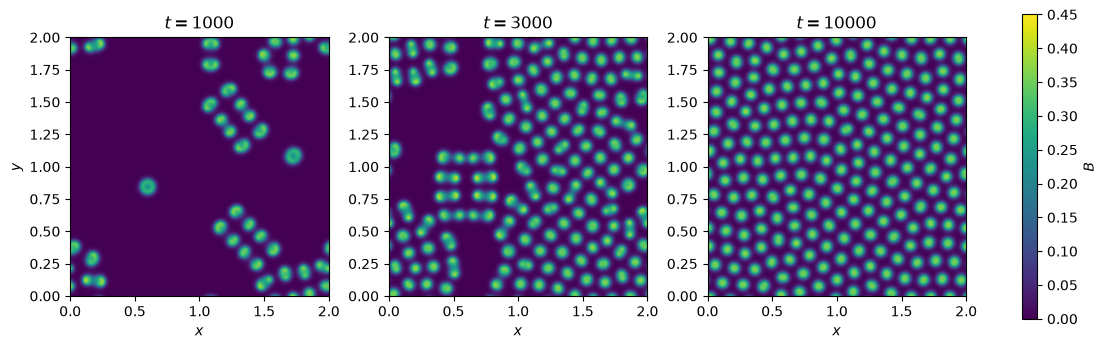

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), constrained_layout=True)
for ax, t, y in zip(axes, sol.ts, sol.ys):
    B = np.asarray(y[N * N:]).reshape(N, N).T
    im = ax.imshow(B, origin="lower", extent=(0, side, 0, side), vmin=0, vmax=0.45)
    ax.set(title=f"$t = {t:.0f}$", xlabel="$x$")
axes[0].set_ylabel("$y$")
fig.colorbar(im, ax=axes, label="$B$", shrink=0.9)
plt.show()

## Check

The seeds split into spots, and the spots divide until they fill the square, the pattern this regime is named for. To check the solve, we compare it with a reference at tolerances a thousand times tighter. `compare` prints the largest difference in $B$ at each snapshot and the number of spots, counted as local maxima of $B$ above 0.2.

In [7]:
reference = ds.pdesolve(problem, ds.JIDA(rtol=1e-9, atol=1e-9), (0.0, T), y0, saveat=ds.SaveAt(ts=TS))

def spot_count(y, n):
    B = y[n * n:].reshape(n, n)
    peak = B > 0.2
    for shift in [(1, 0), (-1, 0), (0, 1), (0, -1), (1, 1), (1, -1), (-1, 1), (-1, -1)]:
        peak &= B >= jnp.roll(B, shift, axis=(0, 1))       # periodic neighbours
    return int(peak.sum())

def compare(sol, n=N):
    diff = jnp.max(jnp.abs(sol.ys[:, n * n:] - reference.ys[:, n * n:]), axis=1)
    print(f"{'':11} max |B - B_ref| at t = 1000, 3000, 10^4: " + ", ".join(f"{d:.0e}" for d in diff)
          + f"   spots: {spot_count(sol.ys[-1], n)} (reference {spot_count(reference.ys[-1], n)})")

compare(sol)

            max |B - B_ref| at t = 1000, 3000, 10^4: 4e-04, 3e-02, 4e-01   spots: 239 (reference 237)


The two runs agree to $4 \times 10^{-4}$ at $t = 1000$ and then drift apart, since a small shift in when one spot divides moves every spot it spawns. The number of spots, 239 against 237, still agrees to within one percent.

## Why an implicit solver

An explicit method such as forward Euler, which computes each step from the current state alone, is stable only for steps $\Delta t \le h^2 / (4 D_A)$ on cells of width $h$. This limit falls fourfold each time the grid is refined. To compare, we record every accepted step of JIDA, an implicit solver, saving `mean_B` instead of the full state.

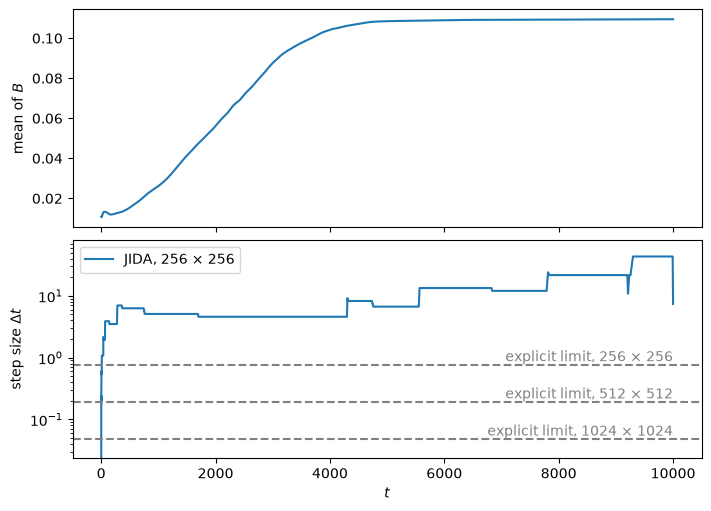

In [8]:
steps = ds.pdesolve(problem, ds.JIDA(), (0.0, T), y0, saveat=ds.SaveAt(steps=True, outputs=("mean_B",)))
ts = np.asarray(steps.ts[: int(steps.valid_count)])
mean_B = np.asarray(steps.outputs["mean_B"][: int(steps.valid_count)])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True, constrained_layout=True)
ax1.plot(ts, mean_B)
ax1.set(ylabel="mean of $B$")
ax2.semilogy(ts[1:], np.diff(ts), label=f"JIDA, {N} × {N}")
for n in (N, 2 * N, 4 * N):
    limit = (side / n) ** 2 / (4 * DA)
    ax2.axhline(limit, ls="--", c="gray")
    ax2.annotate(f"explicit limit, {n} × {n}", (T, 1.15 * limit), color="gray", ha="right")
ax2.set(xlabel="$t$", ylabel=r"step size $\Delta t$", ylim=(limit / 2, None))
ax2.legend(loc="upper left")
plt.show()

JIDA's step size follows how fast the pattern changes, short while the spots divide and the mean of $B$ climbs, and longer once the square fills. The explicit limit, by contrast, ignores the pattern and depends on the grid alone.

Next, we count the fewest forward Euler steps that reach $t = 10^4$ stably on each grid and compare them with JIDA's steps.

In [9]:
for n in GRIDS:
    p_n, y0_n = build(n)
    print(f"{n} x {n}: explicit steps >= {T / ((side / n) ** 2 / (4 * DA)):.0f}")
    timed(p_n, y0_n, ds.JIDA(), "JIDA", saveat=ds.SaveAt())

128 x 128: explicit steps >= 3277


JIDA        compile  1.6 s  run   1.92 s  steps  1720  rejected   2  Newton  2478  factorizations  18  (cudss)
256 x 256: explicit steps >= 13107


JIDA        compile  1.5 s  run   4.19 s  steps  1398  rejected   2  Newton  1905  factorizations  30  (cudss)


512 x 512: explicit steps >= 52429


JIDA        compile  8.7 s  run  16.14 s  steps  1393  rejected   1  Newton  2080  factorizations  26  (cudss)


From the 128 × 128 to the 512 × 512 grid, the explicit count grows from 3277 to 52429, while JIDA takes between 1393 and 1720 steps. Its count follows the pattern each grid resolves, not the stiffness.

## Tolerances

`rtol` and `atol` set how much error each step may make, and we loosen both from the default of `1e-6`.

In [10]:
for tol in (1e-4, 1e-3):
    s = timed(problem, y0, ds.JIDA(rtol=tol, atol=tol), f"tol {tol:.0e}")
    compare(s)

tol 1e-04   compile  1.5 s  run   3.19 s  steps   572  rejected   6  Newton  1059  factorizations  45  (cudss)
            max |B - B_ref| at t = 1000, 3000, 10^4: 1e-02, 8e-02, 4e-01   spots: 242 (reference 237)


tol 1e-03   compile  1.7 s  run  10.20 s  steps   393  rejected  72  Newton   898  factorizations 255  (cudss)
            max |B - B_ref| at t = 1000, 3000, 10^4: 2e-01, 4e-01, 4e-01   spots: 236 (reference 237)


Looser tolerances take fewer steps and make larger errors at $t = 1000$, and at `1e-4` the run is about a quarter faster than the default. At `1e-3`, however, the solver rejects 72 steps and refactors 255 times, so the run takes more than twice as long as the default.

## Choosing the solver

Besides JIDA, diff-soup has two more implicit solvers, JNDF and JBDF, which share its options, so swapping one changes only the class name. All three accept this model, since every equation in it carries a time derivative.

In [11]:
for name, solver in [("JNDF", ds.JNDF()), ("JBDF", ds.JBDF())]:
    s = timed(problem, y0, solver, name)
    compare(s)

JNDF        compile  1.9 s  run   5.93 s  steps   799  rejected   6  Newton  2834  factorizations  64  (cudss)
            max |B - B_ref| at t = 1000, 3000, 10^4: 3e-04, 1e-02, 5e-02   spots: 235 (reference 237)


JBDF        compile  2.7 s  run   4.75 s  steps  1081  rejected   7  Newton  1502  factorizations  74  (cudss)
            max |B - B_ref| at t = 1000, 3000, 10^4: 7e-04, 5e-02, 2e-01   spots: 239 (reference 237)


All three solvers keep the spot count and differ only in steps and cost. JIDA is the recommended default because it solves every differential-algebraic equation (DAE) a recipe can produce, a system that mixes equations with and without time derivatives. JNDF and JBDF need the time derivatives to appear linearly.

## The linear backend

Every Newton iteration solves a linear system in all the unknowns, and its matrix is sparse, with almost all entries zero. `ds.topology_report` counts the nonzeros, which are all that a sparse direct solver factors, together with the fill, the new nonzeros that factoring creates. `linear="auto"` picks cuDSS on a GPU and KLU on a CPU, so we name a backend only inside a device check.

In [12]:
report = ds.topology_report(problem)
print(f"{report.n} unknowns, {report.nnz} nonzeros, {report.n**2 * 8 / 1e9:.0f} GB as a dense float64 matrix")
if GPU:
    p_c, y0_c = build(GRIDS[0])
    timed(p_c, y0_c, ds.JIDA(linear="cudss"), "cuDSS, GPU")
    with jax.default_device(jax.devices("cpu")[0]):
        p_c, y0_c = build(GRIDS[0])
        timed(p_c, y0_c, ds.JIDA(linear="klu"), "KLU, CPU")
else:
    print("No GPU: every run above used KLU.")

131072 unknowns, 1310720 nonzeros, 137 GB as a dense float64 matrix


cuDSS, GPU  compile  1.2 s  run   1.95 s  steps  1720  rejected   2  Newton  2478  factorizations  18  (cudss)


KLU, CPU    compile  3.4 s  run  17.82 s  steps  1720  rejected   2  Newton  2478  factorizations  18  (klu)


On a GPU, both runs use The Well's 128 × 128 grid, since KLU is slow on the finer ones. The run with cuDSS is about nine times faster than the one with KLU.

## Precision

The precision is passed to `spec.build`, so we rebuild the problem for each mode. `fp32_factor` and `fp32_ir` factor the matrix in single precision (float32) but evaluate the residual, how far a state is from solving the equations, in double precision (float64). `fp32` runs everything in float32.

In [13]:
if GPU:
    modes = {"fp64": ds.Precision.fp64(), "fp32_factor": ds.Precision.fp32_factor(),
             "fp32_ir": ds.Precision.fp32_ir(), "fp32": ds.Precision.fp32()}
    for label, precision in modes.items():
        p_lo, y0_lo = build(N, precision)
        compare(timed(p_lo, y0_lo, ds.JIDA(), label))
else:
    print("Reduced precision runs on cuDSS, so it needs a GPU.")

fp64        compile  1.9 s  run   4.20 s  steps  1398  rejected   2  Newton  1905  factorizations  30  (cudss)
            max |B - B_ref| at t = 1000, 3000, 10^4: 4e-04, 3e-02, 4e-01   spots: 239 (reference 237)


fp32_factor compile  2.0 s  run   3.14 s  steps  1399  rejected   1  Newton  1911  factorizations  27  (cudss)
            max |B - B_ref| at t = 1000, 3000, 10^4: 4e-04, 3e-02, 4e-01   spots: 239 (reference 237)


fp32_ir     compile  2.0 s  run   3.21 s  steps  1398  rejected   2  Newton  1906  factorizations  30  (cudss)
            max |B - B_ref| at t = 1000, 3000, 10^4: 4e-04, 3e-02, 4e-01   spots: 239 (reference 237)


fp32        compile  1.8 s  run   2.88 s  steps  1564  rejected   0  Newton  2473  factorizations  23  (cudss)


            max |B - B_ref| at t = 1000, 3000, 10^4: 1e-02, 4e-01, 4e-01   spots: 243 (reference 237)


On the GPU, both mixed modes match `fp64` in steps and error and take three quarters of its time. Their accuracy comes from the float64 residual, against which Newton's method corrects the error of the float32 factor.

`fp32_ir` is the recommended mixed mode. It costs the same as `fp32_factor` and also refines forward-mode derivatives, so `jax.jacfwd` through it reaches double precision.

At tight tolerances on an ill-conditioned DAE, one whose matrix amplifies small errors, both mixed modes fall short of `fp64`, which stays the choice there ([precision](../overview/simulation/precision.md#mixed-precision)).

End-to-end `fp32` is less accurate than the mixed modes, here with an error at $t = 1000$ more than ten times larger. It is meant for a GPU, and on a DAE, float32 rounding can stop it at the start, where the solver makes the initial state satisfy the constraints.